# Step 1 - Load the data


In [96]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

In [97]:
data_path = Path("C:\\Users\\hp\\Desktop\\Deep Learning Project\\mnist-digit-classifier\\data\\mnist.npz")

with np.load(data_path) as data:
    X_train = data["x_train"]
    y_train = data["y_train"]
    X_test = data["x_test"]
    y_test = data["y_test"]

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)

Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


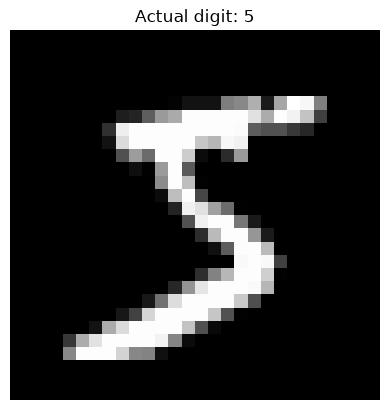

In [98]:
index = 0 # selects the first image.

plt.imshow(X_train[index], cmap="gray")
plt.title(f"Actual digit: {y_train[index]}")
plt.axis("off")
plt.show()

# Step 2 - Prepare the data Convert images into numbers the model can use


In [99]:
# 2.1 Understand the image format

# Select the first training image
image = X_train[0]

print("Image shape:", image.shape)
print("Minimum pixel value:", image.min())
print("Maximum pixel value:", image.max())

Image shape: (28, 28)
Minimum pixel value: 0
Maximum pixel value: 255


In [100]:
# 2.2 Flatten the images

# Convert each image into a row of 784(28 * 28) pixel values
X_train_flat = X_train.reshape(60000, 784)
X_test_flat = X_test.reshape(10000, 784)

print("Training data:", X_train_flat.shape)
print("Testing data:", X_test_flat.shape)

Training data: (60000, 784)
Testing data: (10000, 784)


In [101]:
# 2.3 Normalize the pixel values

# Scale pixel values from 0–255 to 0–1
X_train_normalized = X_train_flat / 255.0
X_test_normalized = X_test_flat / 255.0

print("Minimum value:", X_train_normalized.min())
print("Maximum value:", X_train_normalized.max())

Minimum value: 0.0
Maximum value: 1.0


# Step 3 - Build a simple neural network

In [102]:

# Step 3.1 — Create the model's weights

input_size = 784
hidden_size = 64
output_size = 10

np.random.seed(42)

# He initialization for the ReLU hidden layer
W1 = np.random.randn(input_size, hidden_size) * np.sqrt(2.0 / input_size)

# Xavier initialization for the output layer
W2 = np.random.randn(hidden_size, output_size) * np.sqrt(1.0 / hidden_size)

# Initialize biases
b1 = np.zeros((1, hidden_size))
b2 = np.zeros((1, output_size))

print("Model created!")
print("W1:", W1.shape)
print("W2:", W2.shape)


Model created!
W1: (784, 64)
W2: (64, 10)


In [103]:
# 3.2 Select the first image
image = X_train_normalized[0:1]

# Calculate the hidden layer values
hidden_input = np.dot(image, W1) + b1

print("Image shape:", image.shape)
print("Hidden layer shape:", hidden_input.shape)

Image shape: (1, 784)
Hidden layer shape: (1, 64)


In [104]:
# 3.3 Apply ReLU to the hidden layer
# ReLU is a simple function that changes negative numbers to zero and keeps positive numbers unchanged.

hidden_output = np.maximum(0, hidden_input)
print("Hidden output shape:", hidden_output.shape)

Hidden output shape: (1, 64)


In [105]:
# 3.4 — Calculate the output layer.
# Calculate scores for digits 0–9
output = np.dot(hidden_output, W2) + b2

print("Output shape:", output.shape)
print("Digit scores:", output)

Output shape: (1, 10)
Digit scores: [[-0.39357342  0.63303358 -0.35412086 -0.06639769 -0.43160074 -0.07365949
   0.07296577  0.07454867 -0.31274205  0.45744619]]


In [106]:
# Step 3.5 — Make the first prediction
# Find the digit with the highest score
predicted_digit = np.argmax(output)

print("Predicted digit:", predicted_digit)
print("Actual digit:", y_train[0])

Predicted digit: 1
Actual digit: 5


# Step 4 - Train and evaluate

In [107]:
# Step 4.1 — Use 30,000 training images

X_batch = X_train_normalized[:30000]
y_batch = y_train[:30000]

print("Training images:", X_batch.shape)
print("Training labels:", y_batch.shape)


Training images: (30000, 784)
Training labels: (30000,)


In [108]:
# Step 4.2 — Softmax and Cross-Entropy Loss
#Softmax converts the output scores into probabilities. Cross-entropy loss measures how confidently the model predicts 
# the correct digit.

In [109]:
def softmax(scores):
    # Subtract the maximum score for numerical stability
    scores = scores - np.max(scores, axis=1, keepdims=True)

    # Convert scores into positive values
    exp_scores = np.exp(scores)

    # Convert values into probabilities
    probabilities = exp_scores / np.sum(
        exp_scores, axis=1, keepdims=True
    )

    return probabilities


In [110]:
# Test softmax using the output scores from your first image

probabilities = softmax(output)

print("Probabilities:", probabilities)
print("Sum of probabilities:", np.sum(probabilities))
print("Predicted digit:", np.argmax(probabilities))
print("Actual digit:", y_train[0])


Probabilities: [[0.06589247 0.18394397 0.06854406 0.09139584 0.0634338  0.09073454
  0.10506334 0.10522977 0.07143983 0.15432238]]
Sum of probabilities: 1.0
Predicted digit: 1
Actual digit: 5


In [111]:
# 4.3 What is Cross-Entropy Loss?
# Your neural network predicts probabilities for all 10 digits. Cross-entropy loss measures how far its prediction is 
# from the correct answer.

In [112]:
def cross_entropy_loss(probabilities, y):
    # Get the probability assigned to each correct digit
    correct_probabilities = probabilities[
        np.arange(len(y)), y
    ]

    # Calculate the average loss
    loss = -np.mean(
        np.log(correct_probabilities + 1e-12)
    )

    return loss


In [113]:
probabilities = softmax(output)

loss = cross_entropy_loss(
    probabilities,
    np.array([y_train[0]])
)

print("Actual digit:", y_train[0])
print("Predicted digit:", np.argmax(probabilities))
print("Cross-entropy loss:", loss)


Actual digit: 5
Predicted digit: 1
Cross-entropy loss: 2.399817157851621


In [114]:
# 4.4 Step — Evaluate the Model's Accuracy

# Step 1: Forward propagation
hidden_input = np.dot(X_test_normalized, W1) + b1
hidden_output = np.maximum(0, hidden_input)
output = np.dot(hidden_output, W2) + b2

# Step 2: Convert output scores into probabilities
probabilities = softmax(output)

# Step 3: Find the predicted digit for each image
predictions = np.argmax(probabilities, axis=1)

# Step 4: Calculate accuracy
correct_predictions = np.sum(predictions == y_test)
accuracy = correct_predictions / len(y_test) * 100

print("Correct predictions:", correct_predictions)
print("Total test images:", len(y_test))
print(f"Test accuracy: {accuracy:.2f}%")


Correct predictions: 1042
Total test images: 10000
Test accuracy: 10.42%


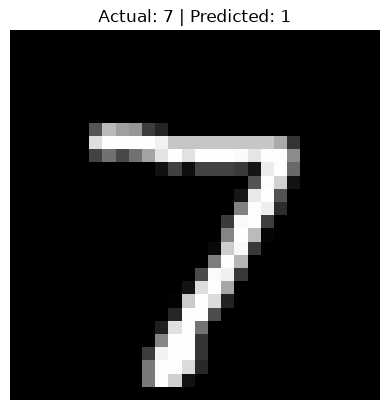

Actual digit: 7
Predicted digit: 1


In [115]:
# Step 4.5 — Inspect the Model's Predictions
# Select one test image
index = 0

# Display the image
plt.imshow(X_test[index], cmap="gray")
plt.title(
    f"Actual: {y_test[index]} | Predicted: {predictions[index]}"
)
plt.axis("off")
plt.show()

print("Actual digit:", y_test[index])
print("Predicted digit:", predictions[index])
 

In [116]:
# Step 4.6 — Train the model

learning_rate = 0.1
epochs = 30

for epoch in range(epochs):

    # 1. Forward propagation
    hidden_input = np.dot(X_batch, W1) + b1
    hidden_output = np.maximum(0, hidden_input)
    output = np.dot(hidden_output, W2) + b2

    probabilities = softmax(output)

    # 2. Calculate loss
    loss = cross_entropy_loss(probabilities, y_batch)

    # 3. Calculate gradients for the output layer
    d_output = probabilities.copy()
    d_output[np.arange(len(y_batch)), y_batch] -= 1
    d_output /= len(y_batch)

    dW2 = np.dot(hidden_output.T, d_output)
    db2 = np.sum(d_output, axis=0, keepdims=True)

    # 4. Calculate gradients for the hidden layer
    d_hidden = np.dot(d_output, W2.T)
    d_hidden[hidden_input <= 0] = 0

    dW1 = np.dot(X_batch.T, d_hidden)
    db1 = np.sum(d_hidden, axis=0, keepdims=True)

    # 5. Update weights and biases
    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1
    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2

    print(
    f"Epoch {epoch + 1}/{epochs} - "
    f"Loss: {loss:.4f} - "
    f"Accuracy: {np.mean(np.argmax(probabilities, axis=1) == y_batch) * 100:.2f}%"
)


Epoch 1/30 - Loss: 2.3611 - Accuracy: 10.84%


Epoch 2/30 - Loss: 2.2985 - Accuracy: 13.12%
Epoch 3/30 - Loss: 2.2447 - Accuracy: 17.51%
Epoch 4/30 - Loss: 2.1951 - Accuracy: 23.93%
Epoch 5/30 - Loss: 2.1476 - Accuracy: 30.26%
Epoch 6/30 - Loss: 2.1011 - Accuracy: 35.84%
Epoch 7/30 - Loss: 2.0553 - Accuracy: 40.35%
Epoch 8/30 - Loss: 2.0098 - Accuracy: 44.15%
Epoch 9/30 - Loss: 1.9646 - Accuracy: 47.52%
Epoch 10/30 - Loss: 1.9194 - Accuracy: 50.49%
Epoch 11/30 - Loss: 1.8744 - Accuracy: 53.03%
Epoch 12/30 - Loss: 1.8294 - Accuracy: 55.23%
Epoch 13/30 - Loss: 1.7845 - Accuracy: 57.18%
Epoch 14/30 - Loss: 1.7396 - Accuracy: 58.89%
Epoch 15/30 - Loss: 1.6948 - Accuracy: 60.74%
Epoch 16/30 - Loss: 1.6503 - Accuracy: 62.50%
Epoch 17/30 - Loss: 1.6063 - Accuracy: 64.16%
Epoch 18/30 - Loss: 1.5628 - Accuracy: 65.83%
Epoch 19/30 - Loss: 1.5203 - Accuracy: 67.19%
Epoch 20/30 - Loss: 1.4787 - Accuracy: 68.54%
Epoch 21/30 - Loss: 1.4383 - Accuracy: 69.79%
Epoch 22/30 - Loss: 1.3991 - Accuracy: 70.89%
Epoch 23/30 - Loss: 1.3613 - Accuracy: 71.

In [117]:
# Step 4.7 — Evaluate the trained model

# Step 1: Forward propagation
hidden_input = np.dot(X_test_normalized, W1) + b1
hidden_output = np.maximum(0, hidden_input)
output = np.dot(hidden_output, W2) + b2

# Step 2: Convert scores into probabilities
probabilities = softmax(output)

# Step 3: Predict the digit
predictions = np.argmax(probabilities, axis=1)

# Step 4: Count correct predictions
correct_predictions = np.sum(predictions == y_test)

# Step 5: Calculate accuracy
accuracy = correct_predictions / len(y_test) * 100

print("Correct predictions:", correct_predictions)
print("Total test images:", len(y_test))
print(f"Test accuracy: {accuracy:.2f}%")


Correct predictions: 7813
Total test images: 10000
Test accuracy: 78.13%


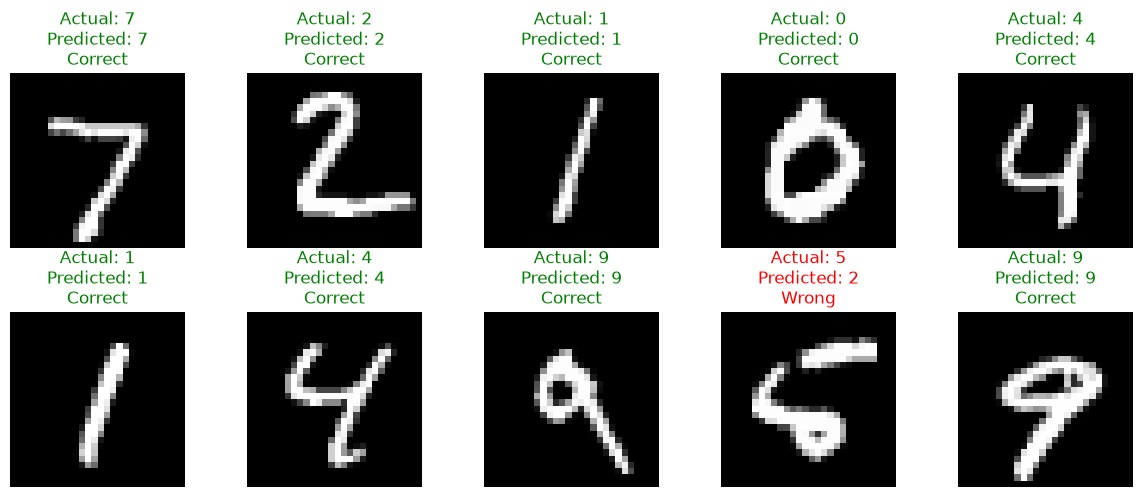

In [118]:
# Step 4.8 — Display predictions with correct/incorrect status

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(X_test[i], cmap="gray")

    if predictions[i] == y_test[i]:
        color = "green"
        status = "Correct"
    else:
        color = "red"
        status = "Wrong"

    plt.title(
        f"Actual: {y_test[i]}\nPredicted: {predictions[i]}\n{status}",
        color=color
    )

    plt.axis("off")

plt.tight_layout()
plt.show()


# Step 5 - Make a prediction on one image

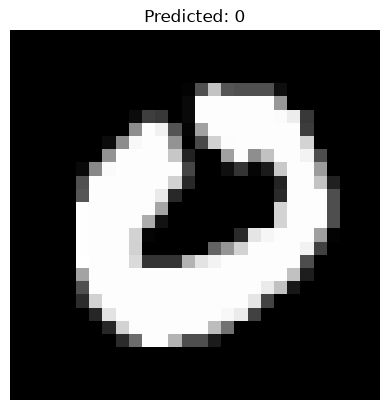

Actual digit: 0
Predicted digit: 0


In [119]:

# Step 5.1 — Predict one handwritten digit

index = 25

image = X_test_normalized[index:index + 1]

# Forward propagation
hidden_input = np.dot(image, W1) + b1
hidden_output = np.maximum(0, hidden_input)
output = np.dot(hidden_output, W2) + b2

# Predict the digit
probabilities = softmax(output)
predicted_digit = np.argmax(probabilities)

# Display the image
plt.imshow(X_test[index], cmap="gray")
plt.title(f"Predicted: {predicted_digit}")
plt.axis("off")
plt.show()

print("Actual digit:", y_test[index])
print("Predicted digit:", predicted_digit)


In [120]:

# Step 5.2 — Display prediction confidence

confidence = probabilities[0, predicted_digit] * 100

print("Predicted digit:", predicted_digit)
print(f"Model confidence: {confidence:.2f}%")


Predicted digit: 0
Model confidence: 89.39%


In [121]:

# Step 5.3 — Show probabilities for every digit

for digit in range(10):
    print(f"Digit {digit}: {probabilities[0, digit] * 100:.2f}%")


Digit 0: 89.39%
Digit 1: 0.09%
Digit 2: 4.73%
Digit 3: 0.30%
Digit 4: 0.72%
Digit 5: 2.66%
Digit 6: 1.03%
Digit 7: 0.16%
Digit 8: 0.85%
Digit 9: 0.06%


In [122]:

# Step 5.4 — Check overall test accuracy

correct_predictions = np.sum(predictions == y_test)
accuracy = correct_predictions / len(y_test) * 100

print(f"Test accuracy: {accuracy:.2f}%")


Test accuracy: 78.13%


In [123]:

# Step 5.5 — Find incorrect predictions

wrong_indices = np.where(predictions != y_test)[0]

print("Total incorrect predictions:", len(wrong_indices))
print("First 10 incorrect image indices:", wrong_indices[:10])


Total incorrect predictions: 2187
First 10 incorrect image indices: [ 8 11 15 33 38 45 46 53 54 59]


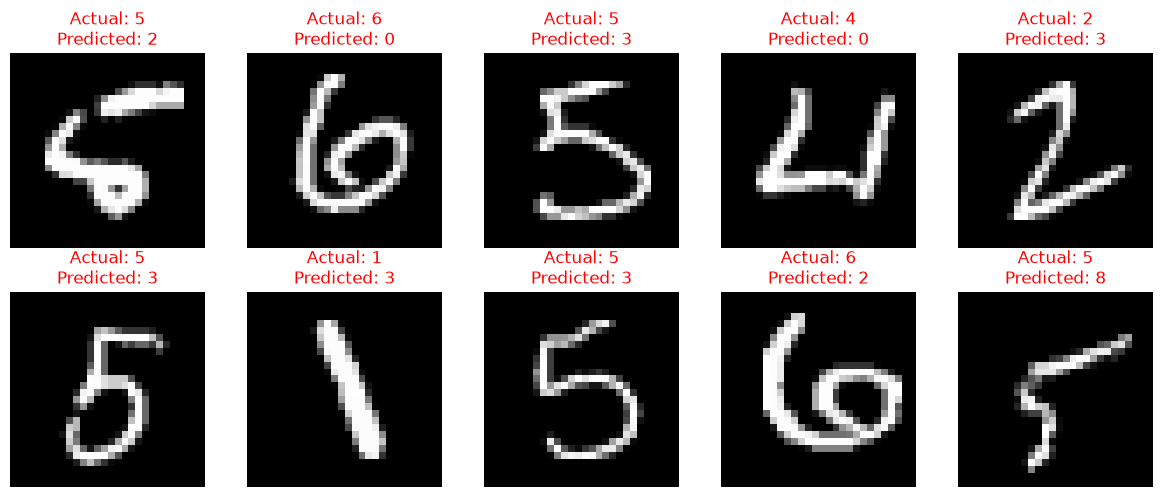

In [124]:

# Step 5.6 — Display 10 incorrect predictions

plt.figure(figsize=(12, 5))

for i in range(10):
    index = wrong_indices[i]

    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[index], cmap="gray")

    plt.title(
        f"Actual: {y_test[index]}\nPredicted: {predictions[index]}",
        color="red"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()


In [125]:
# Step 5.7 — Save the trained model

np.savez(
    "mnist_model.npz",
    W1=W1,
    b1=b1,
    W2=W2,
    b2=b2
)

print("Model saved successfully!")


Model saved successfully!


In [126]:
# Step 5.8 — Load the saved model

with np.load("mnist_model.npz") as model:
    W1 = model["W1"]
    b1 = model["b1"]
    W2 = model["W2"]
    b2 = model["b2"]

print("Model loaded successfully!")


Model loaded successfully!


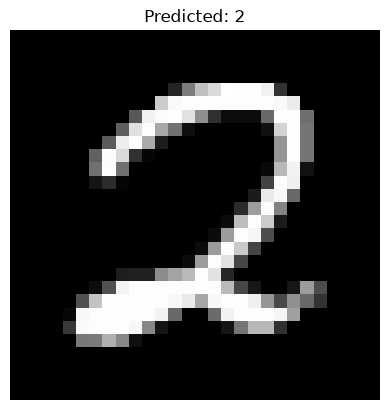

Actual digit: 2
Predicted digit: 2


In [127]:
# Step 5.10 — Predict a digit

index = 35

image = X_test_normalized[index:index + 1]

hidden_input = np.dot(image, W1) + b1
hidden_output = np.maximum(0, hidden_input)
output = np.dot(hidden_output, W2) + b2

probabilities = softmax(output)
predicted_digit = np.argmax(probabilities)

plt.imshow(X_test[index], cmap="gray")
plt.title(f"Predicted: {predicted_digit}")
plt.axis("off")
plt.show()

print("Actual digit:", y_test[index])
print("Predicted digit:", predicted_digit)


# MNIST Handwritten Digit Recognition Using NumPy

## Project Overview
This project uses a simple neural network to recognize handwritten digits from 0 to 9 using the MNIST dataset.

## Technologies Used
- Python
- NumPy
- Matplotlib
- Jupyter Notebook

## Model Architecture
- Input layer: 784 features
- Hidden layer: 64 neurons with ReLU activation
- Output layer: 10 digit scores
- Softmax: converts scores into probabilities

## Training and Evaluation
The model was trained using a subset of the MNIST training dataset. Its performance was evaluated using the separate test dataset.

**Observed test accuracy:** Approximately 80%.

## Key Concepts Learned
- Data loading and preprocessing
- Image flattening and normalization
- Weights and biases
- Forward propagation
- ReLU activation
- Softmax and cross-entropy loss
- Backpropagation and gradient descent
- Model evaluation
- Saving and loading model parameters

## Conclusion
This project demonstrates how a basic neural network can learn to classify handwritten digits using NumPy, without relying on a deep learning framework such as TensorFlow or PyTorch.